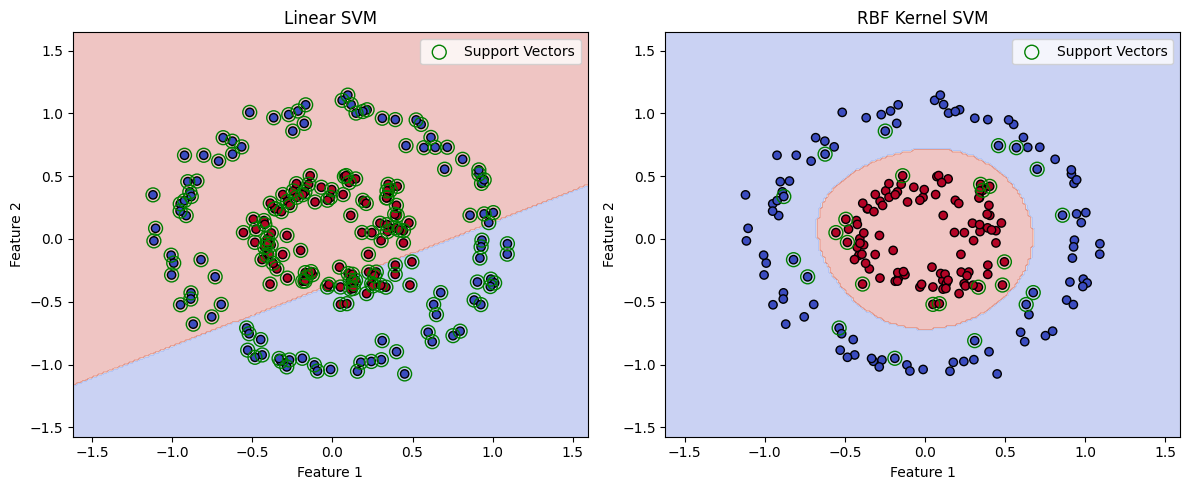

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.svm import SVC

X, y = make_circles(n_samples=200, noise=0.08, factor=0.4, random_state=42)

linear_model = SVC(kernel='linear', C=1)
rbf_model = SVC(kernel='rbf', C=1, gamma=2)

linear_model.fit(X, y)
rbf_model.fit(X, y)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [linear_model, rbf_model]
titles = ['Linear SVM', 'RBF Kernel SVM']

for ax, model, title in zip(axes, models, titles):

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='black')

    ax.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        s=100,
        facecolors='none',
        edgecolors='green',
        label='Support Vectors'
    )

    ax.set_title(title)
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.legend()

plt.tight_layout()
plt.show()
